# UT Dallas Hackathon × PNC Bank — Agentic AI Financial Wellness Lab

**Progressive, reproducible workshop notebook | Synthetic data only**

**Learning path:** 1. Data and 24-month transactions → 2. Eight indicators → 3. What-if → 4. Open vs. closed LLM → 5. Function calling → 6. LangGraph → 7. Evaluation & extensions.

**Core path is offline and requires no API key.** Optional API cells are guarded by environment variables; LangGraph cells run when the optional package is installed. The notebook and companion Python files should remain in the same folder. Do not enter real customer financial data.

**Suggested workshop pacing:** 0–8 challenge; 8–18 dataset/metrics; 18–28 LLMs; 28–40 tools/graph; 40–55 team challenge; 55–60 share-outs. Practice the full notebook after the session.

## 0. Environment and reproducibility
Run from the extracted workshop directory. Suggested setup: `python -m pip install -r requirements.txt`; optional packages: `python -m pip install openai langgraph requests`. Model access is optional. Never put credentials in notebook source control.
For cached Hugging Face models, run this notebook in the environment containing the cache (WSL on the instructor machine). Install `requirements-hf.txt` only if the inference dependencies are missing. Set `ENABLE_HF=1`; default model: `Qwen/Qwen3-VL-2B-Instruct`. No weights are downloaded. See README for CPU/CUDA settings.


In [1]:
from pathlib import Path
import os, json, math, sys
import pandas as pd
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / "financial_tools.py").exists():
    raise FileNotFoundError("Run notebook from extracted workshop directory")
from financial_tools import (get_customer_profile, get_accounts, calculate_indicators, simulate_purchase,
    get_transactions, get_account_history, summarize_transaction_history)
CUSTOMER_ID = "C001"
print("Python:", sys.version.split()[0], "| Workspace:", ROOT)
print("OpenAI key present:", bool(os.getenv("OPENAI_API_KEY")), "| Hugging Face enabled:", os.getenv("ENABLE_HF") == "1")

Python: 3.12.3 | Workspace: /mnt/c/Users/muthu/OneDrive/Documents/GitHub/codex-ai-assisted-coding-demo/PNC_UT_Dallas_Hackathon_Instructor_Lab_Package
OpenAI key present: True | Hugging Face enabled: True


## 1. Explore synthetic household data
**Exercise:** Compare C001 to another customer. Which information is missing for a complete net-worth estimate?

In [2]:
profiles = pd.read_csv(ROOT / "data" / "profiles.csv")
accounts = pd.read_csv(ROOT / "data" / "accounts.csv")
print("Customers:", len(profiles), "Accounts:", len(accounts))
print("Types:", sorted(accounts.account_type.unique().tolist()))
display(profiles.head(3))
display(accounts[accounts.customer_id == CUSTOMER_ID])
display(accounts.groupby("account_type").agg(accounts=("balance", "count"), total_balance=("balance", "sum")).round(2))

Customers: 30 Accounts: 196
Types: ['auto_loan', 'cd', 'checking', 'credit_card', 'ira', 'mortgage', 'personal_loan', 'savings']


,customer_id,monthly_income,monthly_non_debt_expenses,credit_limit
0,C001,9710.63,6359.87,25193.32
1,C002,6094.69,3733.89,24556.92
2,C003,9209.62,6314.28,8819.69


,customer_id,account_type,balance,monthly_payment,apr_pct,account_id,opening_balance,history_start,as_of_date,annual_yield_pct
0,C001,checking,1604.00,0.00,0.0,A-C001-CHECKING,1443.60,2024-11-01,2026-10-31,0.0
1,C001,savings,17416.60,0.00,0.0,A-C001-SAVINGS,15538.56,2024-11-01,2026-10-31,2.5
2,C001,ira,6994.56,0.00,0.0,A-C001-IRA,6058.32,2024-11-01,2026-10-31,3.5
3,C001,credit_card,6571.46,197.14,22.5,A-C001-CREDIT_CARD,6440.03,2024-11-01,2026-10-31,0.0
4,C001,personal_loan,1050.28,29.17,11.0,A-C001-PERSONAL_LOAN,1234.39,2024-11-01,2026-10-31,0.0


,accounts,total_balance
account_type,,
auto_loan,15,206367.33
cd,19,139301.17
checking,30,153313.73
credit_card,30,165274.85
ira,30,1312646.35
mortgage,21,4045657.34
personal_loan,21,141204.97
savings,30,426247.55


### 1a. Explore 24 months of transactions and monthly statements

The generated ledger covers November 2024–October 2026 for every listed account. Stable `account_id` values join snapshots, transactions, and statements. Assets and liabilities are stored positive; signed `balance_change` increases or decreases that account. Transactions preserve the original closing balances.

Checking has paychecks, deposits, withdrawals, bills, and paired transfers. Savings has split-payroll deposits, transfers, withdrawals, direct payments, and interest. CDs/IRAs have contributions and simplified interest accrual. Cards have purchases, interest, fees, and payments. Loans have interest, fees, and payments. Interest is monthly synthetic accrual, not a complete bank accounting model; the IRA omits market gains and tax/eligibility rules.

Internal transfers and checking-to-debt payments have two linked entries and are not extra spending. Direct deposit-account expenses and card purchases count as spending once. Interest/fees are separate charges. Explicit external cash-management transfers calibrate the existing closing balances and are excluded from earned income and spending. The original profile income/expense values and scheduled payments remain snapshot assumptions, not historical averages.

In [3]:
history=summarize_transaction_history(CUSTOMER_ID)
monthly_history=pd.DataFrame(history['months'])
print(history['history_start'], 'through', history['as_of_date'], '| Ledger entries:', history['transaction_count'])
print(history['definitions'])
display(monthly_history)
display(pd.DataFrame(get_account_history(CUSTOMER_ID)).head(12))

2024-11-01 through 2026-10-31 | Ledger entries: 594
Spending counts deposit-account expenses and card purchases once. Debt payments and internal transfers are excluded from spending; interest/fees are shown separately. Asset accrual is non-cash. External transfers are snapshot-calibration flows with unlisted accounts. Income less spending and charges is an accrual activity measure, not checking cash flow.


,paycheck_income,spending,debt_payments,debt_interest,asset_interest,fees,external_transfers_in,external_transfers_out,month,transaction_count,closing_assets,closing_debts,closing_liquid_assets,income_less_spending_and_charges
0,9206.49,6648.96,1595.04,132.07,50.23,0.0,0.0,2222.59,2024-11,25,23293.38,7674.22,17190.08,2425.46
1,9273.76,6820.91,1635.69,132.11,50.48,0.0,0.0,2081.89,2024-12,24,23579.73,7671.24,17444.89,2320.74
2,9278.49,5910.59,1449.86,132.15,50.75,15.0,0.0,3062.48,2025-01,25,23786.36,7668.85,17609.59,3220.75
3,9482.04,6248.09,1511.68,132.17,50.97,5.0,0.0,3120.39,2025-02,27,23813.78,7668.91,17601.46,3096.78
4,9469.23,6330.50,1524.71,132.22,51.25,0.0,0.0,2989.05,2025-03,24,23882.71,7669.13,17629.68,3006.51
5,9304.50,6108.24,1478.89,132.28,51.54,0.0,0.0,3238.54,2025-04,24,23756.89,7666.33,17466.35,3063.98
6,9484.12,6330.19,1526.96,132.31,51.80,0.0,0.0,2860.23,2025-05,25,23968.07,7664.32,17636.62,3021.62
7,9279.43,5828.82,1417.72,132.34,52.10,0.0,0.0,3506.83,2025-06,24,23828.57,7661.28,17453.66,3318.27
8,9499.82,5999.49,1455.79,132.36,52.41,0.0,0.0,3121.51,2025-07,24,24123.89,7657.73,17711.83,3367.97
9,9408.45,5985.45,1452.37,132.38,52.68,0.0,0.0,3024.94,2025-08,26,24439.05,7654.53,17985.24,3290.62


,customer_id,account_id,account_type,month,opening_balance,balance_increases,balance_decreases,closing_balance,transaction_count
0,C001,A-C001-CHECKING,checking,2024-11,1443.60,9171.94,9048.19,1567.35,11
1,C001,A-C001-CHECKING,checking,2024-12,1567.35,9250.89,9074.46,1743.78,11
2,C001,A-C001-CHECKING,checking,2025-01,1743.78,9260.58,9164.50,1839.86,11
3,C001,A-C001-CHECKING,checking,2025-02,1839.86,9479.90,9542.62,1777.14,12
4,C001,A-C001-CHECKING,checking,2025-03,1777.14,9444.10,9499.21,1722.03,11
5,C001,A-C001-CHECKING,checking,2025-04,1722.03,9279.50,9526.09,1475.44,11
6,C001,A-C001-CHECKING,checking,2025-05,1475.44,9456.48,9357.48,1574.44,11
7,C001,A-C001-CHECKING,checking,2025-06,1574.44,9257.12,9518.27,1313.29,11
8,C001,A-C001-CHECKING,checking,2025-07,1313.29,9468.17,9307.07,1474.39,11
9,C001,A-C001-CHECKING,checking,2025-08,1474.39,9397.57,9197.25,1674.71,12


In [4]:
# All transaction access is scoped to the selected synthetic customer.
owned=get_accounts(CUSTOMER_ID)
HISTORY_ACCOUNT=owned[0]['account_id']  # Change to any account_id from owned.
page=get_transactions(CUSTOMER_ID, HISTORY_ACCOUNT, '2026-10-01', '2026-10-31', limit=20)
print('Matching entries:', page['total'], '| Showing:', len(page['items']))
display(pd.DataFrame(page['items']))
# Account-level monthly statements reconcile opening + increases - decreases.
statement_frame=pd.DataFrame(get_account_history(CUSTOMER_ID))
assert ((statement_frame.opening_balance+statement_frame.balance_increases
         -statement_frame.balance_decreases-statement_frame.closing_balance).abs()<.011).all()
assert len(monthly_history)==24
assert abs(monthly_history.iloc[-1].closing_liquid_assets-calculate_indicators(CUSTOMER_ID)['liquid_assets'])<.011
try:
    get_transactions(CUSTOMER_ID, 'A-NOT-OWNED')
    raise AssertionError('Foreign account should be rejected')
except ValueError:
    print('Foreign account rejected; all statements reconciled.')

Matching entries: 11 | Showing: 11


,transaction_id,customer_id,account_id,account_type,posted_date,transaction_type,category,description,amount,balance_change,balance_after,flow_class,transfer_id
0,T0000268,C001,A-C001-CHECKING,checking,2026-10-31,withdrawal,external_cash_management,Synthetic withdrawal to an unlisted external a...,2916.56,-2916.56,1604.00,external_transfer,
1,T0000267,C001,A-C001-CHECKING,checking,2026-10-28,payment,debt_payment,Synthetic linked credit card payment,1534.41,-1534.41,4520.56,internal_transfer,X-C001-credit_card-23-payment
2,T0000266,C001,A-C001-CHECKING,checking,2026-10-25,payment,other_spending,Payment,1004.64,-1004.64,6054.97,expense,
3,T0000265,C001,A-C001-CHECKING,checking,2026-10-21,payment,debt_payment,Synthetic linked personal loan payment,15.21,-15.21,7059.61,internal_transfer,X-C001-personal_loan-23-payment
4,T0000264,C001,A-C001-CHECKING,checking,2026-10-18,withdrawal,groceries,Withdrawal,753.47,-753.47,7074.82,expense,
5,T0000263,C001,A-C001-CHECKING,checking,2026-10-15,paycheck,payroll,Paycheck,4812.61,4812.61,7828.29,income,
6,T0000262,C001,A-C001-CHECKING,checking,2026-10-10,payment,utilities,Payment,1004.63,-1004.63,3015.68,expense,
7,T0000261,C001,A-C001-CHECKING,checking,2026-10-05,transfer_out,investment_contribution,Synthetic linked ira deposit,17.38,-17.38,4020.31,internal_transfer,X-C001-ira-23-deposit
8,T0000260,C001,A-C001-CHECKING,checking,2026-10-05,transfer_out,savings_contribution,Synthetic linked savings deposit,27.28,-27.28,4037.69,internal_transfer,X-C001-savings-23-deposit
9,T0000259,C001,A-C001-CHECKING,checking,2026-10-03,payment,housing,Payment,2260.41,-2260.41,4064.97,expense,


Foreign account rejected; all statements reconciled.


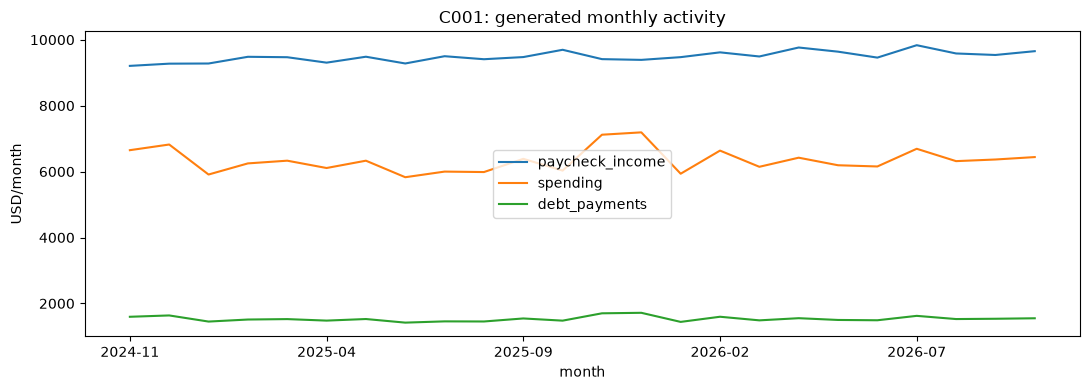

In [5]:
# Plotting is optional; all historical tables work with pandas alone.
try:
    import matplotlib.pyplot as plt
    monthly_history.set_index('month')[['paycheck_income','spending','debt_payments']].plot(
        figsize=(11,4), title=f'{CUSTOMER_ID}: generated monthly activity', ylabel='USD/month')
    plt.tight_layout(); plt.show()
except ImportError:
    print('Optional charts: install requirements-eda.txt. The historical tables above remain usable.')

**Exercise:** Find a loan payment and its checking counterpart using `transfer_id`. Explain why summing all transaction amounts would overstate spending. Compare the latest historical monthly spending with the profile expense assumption. Inspect external transfers and explain why they cannot be interpreted as paychecks or actual savings. The separate EDA notebook validates every running balance and plots all account types across the full history.

## 2. Calculate eight indicators using deterministic code
Tools, not language models, compute arithmetic. Note: *partial* net worth excludes home value and external holdings; emergency reserves count checking and savings only.

In [6]:
indicators = calculate_indicators(CUSTOMER_ID)
display(pd.DataFrame([indicators]).T.rename(columns={0:"C001 value"}))
metrics = ["monthly_cash_surplus", "emergency_fund_months", "debt_payment_to_income_pct", "credit_card_utilization_pct", "savings_rate_pct", "net_worth_partial", "liquid_assets_to_debt_pct", "monthly_debt_payments"]
assert all(key in indicators for key in metrics)
assert indicators["financial_data_scope"].startswith("Partial")
print("8 indicators confirmed")

,C001 value
customer_id,C001
monthly_income,9710.63
monthly_non_debt_expenses,6359.87
monthly_debt_payments,226.31
monthly_cash_surplus,3124.45
net_worth_partial,18393.42
liquid_assets,19020.6
emergency_fund_months,2.89
debt_payment_to_income_pct,2.33
credit_card_utilization_pct,26.08


8 indicators confirmed


### Calculation workshop
1. Cash surplus = income − non-debt expenses − required debt payments. 2. Reserve runway = (checking+savings)/required monthly outflow. 3. Debt-payment ratio = debt payments / income. 4. Credit utilization = credit-card balance / limit. 5. Savings rate = surplus / income. 6. Partial net worth = listed assets − listed debts. 7. Liquidity-to-debt = checking+savings / listed liabilities. 8. Required monthly debt obligations = sum scheduled debt payments.

**Think:** The actual savings rate could differ if there are transfers, payroll deductions, taxes, or spending categories not captured.

## 3. Scenario simulator and sensitivity
Customer question: *If I buy a $30,000 car with $5,000 down, is my monthly cash flow still positive?* This is a simplified financing scenario, not a lending decision.

In [7]:
scenario = simulate_purchase(CUSTOMER_ID, purchase_price=30_000, down_payment=5_000, apr_pct=8.0, term_months=60)
print(json.dumps(scenario, indent=2))
rows=[]
for apr in (0, 5, 8, 12, 16):
    s=simulate_purchase(CUSTOMER_ID, 30_000, 5_000, apr, 60)
    rows.append({"APR (%)":apr,"Payment/month ($)":s["new_monthly_payment"], "Surplus/month ($)":s["projected_monthly_surplus"], "Reserve months":s["projected_emergency_fund_months"]})
display(pd.DataFrame(rows))

{
  "customer_id": "C001",
  "assumptions": {
    "purchase_price": 30000,
    "down_payment": 5000,
    "apr_pct": 8.0,
    "term_months": 60
  },
  "new_monthly_payment": 506.91,
  "projected_monthly_surplus": 2617.54,
  "remaining_liquid_assets": 14020.6,
  "projected_emergency_fund_months": 1.98,
  "caveat": "Excludes taxes, insurance, maintenance, loan fees and future changes; not lending advice."
}


,APR (%),Payment/month ($),Surplus/month ($),Reserve months
0,0,416.67,2707.78,2.00
1,5,471.78,2652.67,1.99
2,8,506.91,2617.54,1.98
3,12,556.11,2568.34,1.96
4,16,607.95,2516.50,1.95


### Test the calculation boundaries
Zero APR should divide principal equally; invalid down payment or negative APR should fail; missing customer ID should fail. Note missing taxes, insurance, maintenance, fees, interest changes, and household behavior.

In [8]:
z=simulate_purchase(CUSTOMER_ID, 12000, 0, 0, 12)
assert abs(z["new_monthly_payment"]-1000)<0.01
for fn in [lambda: simulate_purchase(CUSTOMER_ID, 1000, 2000), lambda: calculate_indicators("NOT_A_CUSTOMER")]:
    try: fn(); raise AssertionError("Expected validation error")
    except ValueError: pass
print("Boundary tests passed")

Boundary tests passed


## 4. Compare local and commercial LLMs
**Equal test conditions:** same evidence, instructions, and review criteria. The prompt tells the model to describe verified facts, never recompute figures, and acknowledge incomplete data. Model outputs can vary.

In [9]:
from llm_demo import build_evidence, narrate
evidence=build_evidence(CUSTOMER_ID)
print(narrate(evidence, provider="none")[:1100])
print("Set ENABLE_HF=1 to use cached Hugging Face weights; set OPENAI_API_KEY to enable cloud call.")

Offline mode: inspect the validated evidence below. Configure an LLM provider for a narrative.
{
  "indicators": {
    "customer_id": "C001",
    "monthly_income": 9710.63,
    "monthly_non_debt_expenses": 6359.87,
    "monthly_debt_payments": 226.31,
    "monthly_cash_surplus": 3124.45,
    "net_worth_partial": 18393.42,
    "liquid_assets": 19020.6,
    "emergency_fund_months": 2.89,
    "debt_payment_to_income_pct": 2.33,
    "credit_card_utilization_pct": 26.08,
    "savings_rate_pct": 32.18,
    "liquid_assets_to_debt_pct": 249.56,
    "credit_card_balance": 6571.46,
    "financial_data_scope": "Partial balance-sheet: excludes home values, external assets, taxes and market changes"
  },
  "scenario": {
    "customer_id": "C001",
    "assumptions": {
      "purchase_price": 30000,
      "down_payment": 5000,
      "apr_pct": 8,
      "term_months": 60
    },
    "new_monthly_payment": 506.91,
    "projected_monthly_surplus": 2617.54,
    "remaining_liquid_assets": 14020.6,
    "pro

In [10]:
# OPTIONAL: already downloaded Hugging Face model; no Ollama server or API key.
# Set HF_MODEL to a cached repository ID or an absolute snapshot directory.
# CUDA defaults to NF4 4-bit; CPU defaults to unquantized float32.
if os.getenv("ENABLE_HF") == "1":
    try: print(narrate(evidence, "huggingface"))
    except Exception as exc: print("Local model unavailable:", type(exc).__name__, str(exc)[:500])
else: print("Skipped local model; set ENABLE_HF=1 to enable cached-model inference.")


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

**Three Useful Considerations:**

1. **Cash Flow Stability**: The customer’s monthly income is stable, but their spending and debt payments are consistent. The projected monthly surplus of $2,617.54 suggests a positive cash flow trend, but it’s important to note that this is based on a new loan scenario and not ongoing income. The current income and expenses are balanced, but the projected surplus assumes a new loan with a 60-month term and 8% APR, which may not reflect real-time financial health.

2. **Emergency Fund and Debt Management**: The customer has a partial emergency fund (2.89 months) and is currently paying 2.33% of income toward debt. While this is manageable, the projected emergency fund is reduced to 1.98 months under the new loan scenario, which could be a concern if unexpected expenses arise. The debt-to-income ratio is moderate, but the high credit card utilization (26%) and ongoing debt payments suggest a need to monitor spending and avoid over-leveraging.

3. **Fina

In [11]:
# OPTIONAL: commercial API. Set OPENAI_API_KEY and optionally OPENAI_MODEL.
# Account charges and model access depend on your API configuration.
if os.getenv("OPENAI_API_KEY"):
    try: print(narrate(evidence,"openai"))
    except Exception as exc: print("API call failed:",type(exc).__name__,str(exc)[:220])
else: print("Skipped cloud LLM (no API key).")

Here’s a concise educational readout based only on the **synthetic data provided**. **Balances are partial** and the balance-sheet scope **excludes home values, external assets, taxes, and market changes**.

### 1) Current cash-flow looks positive
**Observation:** The indicators show about **$9,710.63** monthly income, **$6,359.87** in monthly non-debt expenses, **$226.31** in monthly debt payments, and a **$3,124.45** monthly cash surplus.  
**Why it matters:** That suggests room in the current snapshot for saving goals or handling some added costs.

**Historical context:** In the recent transaction months, **income less spending and charges** was about **$3,038 to $3,134** per month. That historical activity measure is broadly similar, but it is **not the same as checking cash flow**. Also, **external transfers out** appear in each recent month and should **not** be treated as regular spending, and there are **no external transfers in counted as income**.

### 2) Liquidity exists, bu

### Model evaluation mini-rubric
Score each response 0–2 on: (1) numeric fidelity; (2) grounding in provided data; (3) missing-data caveats; (4) clear customer wording; (5) absence of unsupported advice. Report run time and token/API costs separately if available. Do not assume the cloud or local model always wins.

## 5. Build safe tools and a dispatcher
A tool contract limits the operations the model may request. Server-side code still must validate authorization and input bounds. Our tools are read-only or scenario-only, with no transactions.

In [12]:
TOOL_DEFS = [
 {"type":"function","name":"summarize_transaction_history","description":"Retrieve 24-month synthetic activity for an authorized customer; transfers are excluded from spending.","strict":True,"parameters":{"type":"object","properties":{"customer_id":{"type":"string"}},"required":["customer_id"],"additionalProperties":False}},
 {"type":"function","name":"calculate_financial_health","description":"Retrieve verified financial indicators for one authorized synthetic customer.","strict":True,"parameters":{"type":"object","properties":{"customer_id":{"type":"string","description":"Synthetic customer identifier, e.g. C001"}},"required":["customer_id"],"additionalProperties":False}},
 {"type":"function","name":"simulate_vehicle_purchase","description":"Calculate an illustrative vehicle financing scenario for an authorized synthetic customer.","strict":True,"parameters":{"type":"object","properties":{"customer_id":{"type":"string"},"purchase_price":{"type":"number"},"down_payment":{"type":"number"},"apr_pct":{"type":"number"},"term_months":{"type":"integer"}},"required":["customer_id","purchase_price","down_payment","apr_pct","term_months"],"additionalProperties":False}}
]
ALLOWED_CUSTOMERS={"C001","C002","C003"}  # Illustrative session scope, NOT production authorization.
def dispatch_tool(name, args):
    if not isinstance(args,dict) or args.get("customer_id") not in ALLOWED_CUSTOMERS: raise ValueError("Customer not authorized for this demo session")
    if name == "summarize_transaction_history":
        if set(args)!={"customer_id"}: raise ValueError("Unexpected arguments")
        history=summarize_transaction_history(args["customer_id"])
        return {k:history[k] for k in ("customer_id","history_start","as_of_date","totals","definitions")} | {"recent_months":history["months"][-3:]}
    if name == "calculate_financial_health":
        if set(args)!={"customer_id"}: raise ValueError("Unexpected arguments")
        return calculate_indicators(args["customer_id"])
    if name == "simulate_vehicle_purchase":
        if set(args)!={"customer_id","purchase_price","down_payment","apr_pct","term_months"}: raise ValueError("Missing or unexpected arguments")
        if not (0<=args["purchase_price"]<=150000 and 0<=args["down_payment"]<=args["purchase_price"] and 0<=args["apr_pct"]<=35 and 6<=args["term_months"]<=120): raise ValueError("Scenario outside demo bounds")
        return simulate_purchase(**args)
    raise ValueError("Unknown tool")
print(json.dumps(dispatch_tool("calculate_financial_health", {"customer_id":CUSTOMER_ID}),indent=2))

{
  "customer_id": "C001",
  "monthly_income": 9710.63,
  "monthly_non_debt_expenses": 6359.87,
  "monthly_debt_payments": 226.31,
  "monthly_cash_surplus": 3124.45,
  "net_worth_partial": 18393.42,
  "liquid_assets": 19020.6,
  "emergency_fund_months": 2.89,
  "debt_payment_to_income_pct": 2.33,
  "credit_card_utilization_pct": 26.08,
  "savings_rate_pct": 32.18,
  "liquid_assets_to_debt_pct": 249.56,
  "credit_card_balance": 6571.46,
  "financial_data_scope": "Partial balance-sheet: excludes home values, external assets, taxes and market changes"
}


## 5a. OPTIONAL — LLM-mediated function calling through the Responses API
Flow: model proposes function call → application validates and executes → application returns `function_call_output` → model explains grounded output. Never execute arbitrary code or unknown tool names. Tool calls could be absent; handle that case. Loop bounded to 3 iterations.

In [13]:
def openai_tool_chat(question, model=None, customer_id=CUSTOMER_ID):
    if not os.getenv("OPENAI_API_KEY"):
        return {"status":"skipped", "reason":"OPENAI_API_KEY not set"}
    from openai import OpenAI
    client=OpenAI(); chosen=model or os.getenv("OPENAI_MODEL","gpt-5.4")
    instruction=("You are an educational assistant restricted to synthetic customers. "
        "Only use tool-returned financial values; always include uncertainty and missing expenses. "
        "Never claim credit approval, recommend individual securities, or execute transfers. "
        f"The authorized customer_id is {customer_id}. Reject requests about other customers.")
    history=[{"role":"user","content":question}]; trace=[]
    for step in range(3):
        response=client.responses.create(model=chosen,instructions=instruction,tools=TOOL_DEFS,input=history)
        history.extend(response.output)  # Preserve reasoning items as well as tool requests.
        calls=[item for item in response.output if item.type=="function_call"]
        if not calls: return {"status":"complete","answer":response.output_text,"trace":trace}
        for item in calls:
            try:
                args=json.loads(item.arguments)
                if args.get("customer_id")!=customer_id: raise ValueError("Outside authorized customer")
                result=dispatch_tool(item.name,args)
                trace.append({"tool":item.name,"arguments":args,"status":"ok"})
                payload={"ok":True,"result":result}
            except Exception as exc:
                trace.append({"tool":item.name,"status":"rejected","reason":str(exc)})
                payload={"ok":False,"error":str(exc)}
            history.append({"type":"function_call_output","call_id":item.call_id,"output":json.dumps(payload)})
    return {"status":"limit_reached","trace":trace}
if os.getenv("RUN_OPENAI_TOOLS")=="1":
    try: print(json.dumps(openai_tool_chat("For C001, calculate my financial health, then simulate a $30,000 car with $5,000 down, 8% APR and 60 months."),indent=2))
    except Exception as exc: print("Optional API step failed:",type(exc).__name__,str(exc)[:220])
else: print("Skipped paid API tool calls; set RUN_OPENAI_TOOLS=1 and OPENAI_API_KEY to run.")

{
  "status": "complete",
  "answer": "Here\u2019s the tool-based summary for synthetic customer **C001**.\n\n## Financial health\n- **Monthly income:** **$9,710.63**\n- **Monthly non-debt expenses:** **$6,359.87**\n- **Monthly debt payments:** **$226.31**\n- **Monthly cash surplus:** **$3,124.45**\n\n### Key indicators\n- **Liquid assets:** **$19,020.60**\n- **Partial net worth:** **$18,393.42**\n- **Emergency fund:** **2.89 months**\n- **Debt payment-to-income:** **2.33%**\n- **Credit card utilization:** **26.08%**\n- **Savings rate:** **32.18%**\n- **Liquid assets to debt:** **249.56%**\n- **Credit card balance:** **$6,571.46**\n\n## Vehicle scenario\nAssumptions used:\n- **Purchase price:** **$30,000**\n- **Down payment:** **$5,000**\n- **APR:** **8%**\n- **Term:** **60 months**\n\n### Simulation results\n- **Estimated new monthly payment:** **$506.91**\n- **Projected monthly surplus after payment:** **$2,617.54**\n- **Remaining liquid assets after down payment:** **$14,020.60**\n-

## 6. LangGraph orchestration: route → compute → validate → explain
This is a **workflow of specialized nodes**, not automatically an autonomous multi-agent collective. Offline routing makes it reproducible. Extend by replacing the router with a model decision and adding checkpointing/human review. Install `langgraph` to execute.

In [14]:
try:
    from langgraph.graph import StateGraph, START, END
    from typing import TypedDict, Any
    class FinanceState(TypedDict, total=False):
        customer_id: str
        question: str
        intent: str
        metrics: dict
        scenario: dict
        history: dict
        validated: bool
        answer: str
        trace: list[str]
    def route_node(state: FinanceState):
        text=state["question"].lower()
        intent="scenario" if any(term in text for term in ["car", "vehicle", "buy", "purchase", "what if"]) else "metrics"
        if any(term in text for term in ["transaction", "history", "spending"]): intent="history"
        return {"intent":intent,"trace":["router:"+intent]}
    def metrics_node(state: FinanceState):
        return {"metrics":dispatch_tool("calculate_financial_health",{"customer_id":state["customer_id"]}),"trace":state["trace"]+["metrics"]}
    def scenario_node(state: FinanceState):
        args={"customer_id":state["customer_id"],"purchase_price":30000,"down_payment":5000,"apr_pct":8.0,"term_months":60}
        return {"scenario":dispatch_tool("simulate_vehicle_purchase",args),"trace":state["trace"]+["scenario"]}
    def history_node(state: FinanceState):
        return {"history":dispatch_tool("summarize_transaction_history",{"customer_id":state["customer_id"]}),"trace":state["trace"]+["history"]}
    def validate_node(state: FinanceState):
        valid=bool(state.get("metrics") or state.get("scenario") or state.get("history"))
        return {"validated":valid,"trace":state["trace"]+["validation"]}
    def explain_node(state: FinanceState):
        if not state.get("validated"): return {"answer":"No validated figures to explain.","trace":state["trace"]+["blocked"]}
        if state["intent"]=="history":
            h=state["history"]; totals=h["totals"]
            msg=(f"History {h['history_start']} through {h['as_of_date']}: paychecks ${totals['paycheck_income']:,.2f}; "
                 f"spending ${totals['spending']:,.2f}. Internal/external transfers excluded from spending; charges shown separately.")
        elif state["intent"]=="scenario":
            sc=state["scenario"]
            msg=f"Illustrative vehicle payment: ${sc['new_monthly_payment']:,.2f}/month; surplus: ${sc['projected_monthly_surplus']:,.2f}/month; reserves after down payment: ${sc['remaining_liquid_assets']:,.2f}."
        else:
            m=state["metrics"]
            msg=f"Monthly cash surplus: ${m['monthly_cash_surplus']:,.2f}; liquid assets: ${m['liquid_assets']:,.2f}; emergency reserves: {m['emergency_fund_months']} months."
        return {"answer":msg+" Synthetic, incomplete data; not financial advice.","trace":state["trace"]+["explain"]}
    builder=StateGraph(FinanceState)
    for name,node in [("router",route_node),("metrics",metrics_node),("scenario",scenario_node),("history",history_node),("validate",validate_node),("explain",explain_node)]:builder.add_node(name,node)
    builder.add_edge(START,"router")
    builder.add_conditional_edges("router",lambda st:st["intent"],{"metrics":"metrics","scenario":"scenario","history":"history"})
    builder.add_edge("history","validate");builder.add_edge("metrics","validate");builder.add_edge("scenario","validate")
    builder.add_edge("validate","explain");builder.add_edge("explain",END)
    graph=builder.compile()
    for q in ("Summarize my financial health", "What if I buy a car?", "Summarize my transaction history"):
        result=graph.invoke({"customer_id":CUSTOMER_ID,"question":q,"trace":[]})
        print(q,"\n",result["answer"],"\nTRACE:"," → ".join(result["trace"]),"\n")
except ImportError:
    print("LangGraph not installed. Optional: python -m pip install langgraph")

Summarize my financial health 
 Monthly cash surplus: $3,124.45; liquid assets: $19,020.60; emergency reserves: 2.89 months. Synthetic, incomplete data; not financial advice. 
TRACE: router:metrics → metrics → validation → explain 

What if I buy a car? 
 Illustrative vehicle payment: $506.91/month; surplus: $2,617.54/month; reserves after down payment: $14,020.60. Synthetic, incomplete data; not financial advice. 
TRACE: router:scenario → scenario → validation → explain 

Summarize my transaction history 
 History 2024-11-01 through 2026-10-31: paychecks $227,699.61; spending $152,234.49. Internal/external transfers excluded from spending; charges shown separately. Synthetic, incomplete data; not financial advice. 
TRACE: router:history → history → validation → explain 



### Architecture and stretch ideas
`UI → authenticated API → router → [account/health/forecast/simulation tools] → validation → grounded explanation`. A production implementation needs signed-in user identity and account-level authorization, isolated model context, auditability, appropriate data provenance, tracing, consent, prompt-injection controls, tool limits, reviews for consequential actions, and privacy controls.

**Stretch:** design a cash-flow calendar, projected obligation schedule, a digital twin, or a proactive early-warning agent. Validate deterministic predictions independently of LLM language.

## 7. Verification, assignments, and demo checklist
**15-minute team challenge:** Choose a coach, 6+ metric dashboard, what-if simulator, or tool-based router. Deliver a demonstration using C001 and one additional profile. Test invalid inputs and document two explicit limitations.

**Suggested (not official sponsor) rubric:** Customer value 25%, novelty 20%, working prototype 20%, appropriate AI architecture 15%, trustworthiness 15%, communication 5%.

**Discussion prompts:** Does a customer need a score or a helpful explanation? When is a single tool-using model enough? How do model quality and privacy requirements affect deployment?

**References:** [OpenAI function calling](https://developers.openai.com/api/docs/guides/function-calling), [LangGraph](https://docs.langchain.com/oss/python/langgraph/overview), [Ollama](https://docs.ollama.com/), [Streamlit](https://docs.streamlit.io/), [CFPB financial well-being](https://www.consumerfinance.gov/consumer-tools/educator-tool/financial-well-being-resources/).

In [15]:
import unittest
suite=unittest.defaultTestLoader.discover(str(ROOT),pattern="test_*.py")
result=unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful(), "Starter tests failed"
print("Lab complete. Build one new feature and add one test of your own!")

..............
----------------------------------------------------------------------
Ran 14 tests in 3.891s

OK


Lab complete. Build one new feature and add one test of your own!
